# Requirements


pandas==3.0.5
numpy==2.5.0
scikit-learn==1.5.2
statsmodels==0.15.0
scipy==1.18.1
matplotlib==3.11.0
lifelines==0.30.3


# Descriptive statistics

In [26]:
# @title Continuous Baseline Characteristics Analysis (Mann-Whitney U Test)
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

# Load the clinical dataset
df = pd.read_excel('Supplementary data.xlsx')

# Unify column names by stripping whitespace and converting to lowercase
df.columns = [str(c).strip().lower() for c in df.columns]
print("Standardized columns:", df.columns)

# Define the grouping variable (0 = Control, 1 = Modulation)
group_col = 'group'

# List of categorical/binary variables to exclude from the continuous analysis
categorical_vars = [
    'sex', 'death', 'sepsis', 'septic_shock', 'cerebral_disorder',
    'malignant_tumors', 'hepatic_disorders', 'respiratory_disorders',
    'kidney_disorders', 'cardiovascular_disorders', 'mechanical_ventilation',
    'group'  # Explicitly excluding the grouping variable itself
]

# Select numerical columns EXCLUDING the categorical variables listed above
num_cols = [
    col for col in df.select_dtypes(include=['int64', 'float64']).columns
    if col not in categorical_vars
]

print("Automatically selected continuous variables for analysis:", num_cols)

# Helper function to convert data to numeric format safely
def safe_numeric(series):
    return pd.to_numeric(series, errors='coerce')

results = []

for col in num_cols:
    # Separate data into treatment and control groups
    s0 = safe_numeric(df[df[group_col] == 0][col])
    s1 = safe_numeric(df[df[group_col] == 1][col])

    # Filter out missing values (complete cases for individual variables)
    s1_clean = s1.dropna()
    s0_clean = s0.dropna()

    # Ensure there are enough samples to perform the statistical test
    if len(s1_clean) > 1 and len(s0_clean) > 1:
        try:
            # Perform two-sided Mann-Whitney U test
            u_stat, p_val = mannwhitneyu(s1_clean, s0_clean, alternative='two-sided')

            # Calculate median and interquartile range (IQR)
            med1, med0 = s1_clean.median(), s0_clean.median()
            q1_25, q1_75 = s1_clean.quantile(0.25), s1_clean.quantile(0.75)
            q0_25, q0_75 = s0_clean.quantile(0.25), s0_clean.quantile(0.75)

            # Format descriptive statistics as "Median [25th–75th Percentile]"
            group1_str = f"{med1:.2f} [{q1_25:.2f}–{q1_75:.2f}]"
            group0_str = f"{med0:.2f} [{q0_25:.2f}–{q0_75:.2f}]"

            results.append({
                'Parameter': col,
                'Group 0 (Control)': group0_str,
                'Group 1 (Modulation)': group1_str,
                'p-value': p_val
            })
        except Exception:
            continue

# Compile and format the final summary table
if results:
    res_df = pd.DataFrame(results)

    # Sort by p-value to highlight variables with the most prominent differences
    res_df = res_df.sort_values('p-value')

    # Round p-values to two decimal places
    res_df['p-value'] = res_df['p-value'].round(2)

    # Calculate the exact count of missing entries for each parameter
    missing_counts = df[res_df['Parameter']].isna().sum()

    # Map the missing value counts back to the summary dataframe
    res_df['Missing Count'] = res_df['Parameter'].map(missing_counts)

# Display the final structured dataframe
res_df



Standardized columns: Index(['patient_id', 'age', 'sex', 'sofa', 'sepsis', 'septic_shock',
       'cerebral_disorder', 'malignant_tumors', 'hepatic_disorders',
       'respiratory_disorders', 'kidney_disorders', 'cardiovascular_disorders',
       'bwi', 'los_icu', 'death', 'mechanical_ventilation', 'creatinine',
       'inr', 'alt', 'ast', 'wbc', 'plt', 'lac', 'group'],
      dtype='object')
Automatically selected continuous variables for analysis: ['patient_id', 'age', 'sofa', 'bwi', 'los_icu', 'creatinine', 'inr', 'ast', 'wbc', 'plt', 'lac']


,Parameter,Group 0 (Control),Group 1 (Modulation),p-value,Missing Count
4,los_icu,4.00 [2.00–6.50],7.00 [5.00–12.00],0.00,1
2,sofa,3.00 [2.00–4.00],4.00 [3.00–5.00],0.01,0
0,patient_id,11.00 [6.50–15.50],19.00 [9.00–26.00],0.01,0
7,ast,39.00 [22.50–98.25],21.50 [14.00–44.00],0.04,4
10,lac,2.45 [1.73–4.05],2.25 [1.27–2.40],0.08,2
5,creatinine,111.00 [86.00–149.00],92.50 [76.00–117.00],0.10,3
3,bwi,27.00 [23.00–31.25],27.00 [23.00–31.00],0.55,10
9,plt,268.50 [164.50–316.25],207.00 [153.25–320.75],0.58,2
8,wbc,8.25 [5.12–14.55],8.95 [6.90–11.00],0.85,2
6,inr,1.15 [1.02–1.30],1.19 [1.08–1.25],0.94,2


In [28]:
# @title Categorical Baseline Characteristics Analysis (Fisher's Exact Test)
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact

# Define the grouping variable
group_col = 'group'

# Calculate the total number of patients in each group
total_group_0 = len(df[df[group_col] == 0])
total_group_1 = len(df[df[group_col] == 1])

print(f"Total cohort size: Group 0 (Control) = {total_group_0}, Group 1 (Modulation) = {total_group_1}")

results = []

# List of categorical clinical variables to evaluate
categorical_vars = [
    'sex', 'death', 'sepsis', 'septic_shock', 'cerebral_disorder',
    'malignant_tumors', 'hepatic_disorders', 'respiratory_disorders',
    'kidney_disorders', 'cardiovascular_disorders', 'mechanical_ventilation'
]

for var in categorical_vars:
    # Extract data for each group and drop missing entries
    group_0_data = df[df[group_col] == 0][var].dropna()
    group_1_data = df[df[group_col] == 1][var].dropna()

    # Calculate absolute frequencies (counts of events)
    sum_group_0 = int(group_0_data.sum())
    sum_group_1 = int(group_1_data.sum())

    # Calculate relative frequencies (percentages) with zero-division protection
    percent_group_0 = (sum_group_0 / total_group_0 * 100) if total_group_0 > 0 else 0.0
    percent_group_1 = (sum_group_1 / total_group_1 * 100) if total_group_1 > 0 else 0.0

    # Format descriptive statistics as "Count (Percentage%)"
    group0_str = f"{sum_group_0} ({percent_group_0:.1f}%)"
    group1_str = f"{sum_group_1} ({percent_group_1:.1f}%)"

    # Construct the 2x2 contingency table for Fisher's exact test
    # Rows: Event present / Event absent
    # Columns: Group 0 / Group 1
    contingency_table = np.array([
        [sum_group_0, sum_group_1],
        [total_group_0 - sum_group_0, total_group_1 - sum_group_1]
    ])

    # Execute Fisher's exact test
    try:
        odds_ratio, p_value = fisher_exact(contingency_table)
        p_value_formatted = f"{p_value:.4f}"
    except Exception as e:
        print(f"Statistical error executing Fisher's test for variable '{var}': {e}")
        p_value_formatted = "Error"

    results.append({
        'Variable': var,
        'Group 0 (Control)': group0_str,
        'Group 1 (Modulation)': group1_str,
        'p-value (Fisher\'s Exact)': p_value_formatted
    })

# Compile and format the final structured summary table
if results:
    res_df = pd.DataFrame(results)

    # Clean up redundant column names formatting if present
    numeric_columns = [
        'median (g 0)', 'median (g 1)', 'F-stat', 'p-value',
        'percentage (g 0), %', 'percentage (g 1), %'
    ]
    for col in numeric_columns:
        if col in res_df.columns:
            res_df[col] = res_df[col].round(2)

# Display the summary dataframe
res_df



Total cohort size: Group 0 (Control) = 27, Group 1 (Modulation) = 29


,Variable,Group 0 (Control),Group 1 (Modulation),p-value (Fisher's Exact)
0,sex,14 (51.9%),21 (72.4%),0.1676
1,death,12 (44.4%),5 (17.2%),0.0415
2,sepsis,12 (44.4%),16 (55.2%),0.5932
3,septic_shock,7 (25.9%),12 (41.4%),0.2673
4,cerebral_disorder,12 (44.4%),6 (20.7%),0.0861
5,malignant_tumors,6 (22.2%),8 (27.6%),0.7612
6,hepatic_disorders,6 (22.2%),6 (20.7%),1.0000
7,respiratory_disorders,18 (66.7%),15 (51.7%),0.2889
8,kidney_disorders,8 (29.6%),8 (27.6%),1.0000
9,cardiovascular_disorders,14 (51.9%),16 (55.2%),1.0000


# propensity score adjustment

In [29]:
# @title Propensity Score Adjusted Regression Analysis
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np

def run_propensity_score_analysis(df, treatment_col, outcome_col, confounders):
    """
    Performs an outcome analysis adjusted for the Propensity Score (PS used as a covariate).

    Parameters:
    df (pd.DataFrame): The source clinical dataset.
    treatment_col (str): Column name for the intervention variable (Modulation: 1/0).
    outcome_col (str): Column name for the primary endpoint variable (In-hospital mortality: 1/0).
    confounders (list): List of column names representing baseline confounders (e.g., SOFA, lactate).

    Returns:
    statsmodels.iolib.summary.Summary: Summary object containing final regression results.
    """
    # Create a copy of the dataframe to protect the source data
    data = df.copy()

    # --- STEP 1: Propensity Score Estimation ---
    # Construct the formula for the treatment assignment logistic regression
    formula_ps = f"{treatment_col} ~ " + " + ".join(confounders)

    # Fit the logistic regression model to estimate probability of treatment assignment
    ps_model = smf.logit(formula_ps, data=data).fit(disp=0)

    # Store the predicted probabilities as the individual propensity scores
    data['propensity_score'] = ps_model.predict(data)

    print("=== Step 1: Propensity Score Estimation Completed Successfully ===")
    print(f"Calculated PS Range: From {data['propensity_score'].min():.4f} to {data['propensity_score'].max():.4f}\n")

    # --- STEP 2: Propensity Score Adjusted Outcome Model ---
    # The outcome model includes only the treatment indicator and the calculated propensity score
    formula_outcome = f"{outcome_col} ~ {treatment_col} + propensity_score"

    # Fit the final multivariable logistic regression model for hospital mortality
    outcome_model = smf.logit(formula_outcome, data=data).fit(disp=0)

    print("=== Step 2: Final Outcome Regression Results ===")

    # Calculate Odds Ratios (OR) and their corresponding 95% Confidence Intervals (CI)
    params = outcome_model.params
    conf = outcome_model.conf_int()
    odds_ratios = pd.DataFrame(np.exp(pd.concat([params, conf], axis=1)))
    odds_ratios.columns = ['Odds Ratio', '95% CI Lower', '95% CI Upper']
    odds_ratios['p-value'] = outcome_model.pvalues

    print("\nOdds Ratios (OR) Summary Table:")
    print(odds_ratios.round(4))

    return outcome_model.summary()



In [32]:
# @title Missing Data Imputation using K-Nearest Neighbors (KNN) with Seed Setting
import random
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# Set global random seeds to ensure computational reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Load the clinical dataset
supp = pd.read_excel('Supplementary data.xlsx')

# Automatically identify all numerical columns requiring imputation
numeric_cols = supp.select_dtypes(include=['number']).columns

# Initialize the KNN Imputer (set to 5 nearest neighbors as standard for small samples)
imputer = KNNImputer(n_neighbors=5)

# Execute KNN imputation to fill missing values while preserving variance
supp[numeric_cols] = imputer.fit_transform(supp[numeric_cols])

# Verify dataset structure post-imputation
print("Dataset columns processed successfully:", supp.columns)


Dataset columns processed successfully: Index(['Patient_ID', 'Age', 'Sex', 'SOFA', 'Sepsis', 'Septic_Shock',
       'Cerebral_disorder', 'Malignant_tumors', 'Hepatic_disorders',
       'Respiratory_disorders', 'Kidney_disorders', 'Cardiovascular_disorders',
       'BWI', 'LOS_ICU', 'Death', 'Mechanical_ventilation', 'Creatinine',
       'INR', 'ALT', 'AST', 'WBC', 'PLT', 'Lac', 'Group'],
      dtype='object')


In [33]:
# @title Execute Propensity Score Adjusted Analysis
# Define the baseline clinical confounders used to calculate the Propensity Score
confs = [
    'SOFA',
    'Lac',
    'Mechanical_ventilation',
    'Septic_Shock',
    'Malignant_tumors'
]

# Run the multivariable logistic regression adjusted for individual Propensity Scores
summary = run_propensity_score_analysis(
    df=supp,
    treatment_col='Group',   # Intervention indicator: 1 = Modulation, 0 = Control
    outcome_col='Death',     # Primary outcome: 1 = Deceased, 0 = Survived
    confounders=confs
)

# Display the comprehensive statsmodels regression summary
print(summary)


=== Step 1: Propensity Score Estimation Completed Successfully ===
Calculated PS Range: From 0.0304 to 0.9970

=== Step 2: Final Outcome Regression Results ===

Odds Ratios (OR) Summary Table:
                  Odds Ratio  95% CI Lower  95% CI Upper  p-value
Intercept             0.7292        0.2621        2.0289   0.5453
Group                 0.2219        0.0399        1.2345   0.0855
propensity_score      1.3992        0.1173       16.6875   0.7906
                           Logit Regression Results                           
Dep. Variable:                  Death   No. Observations:                   56
Model:                          Logit   Df Residuals:                       53
Method:                           MLE   Df Model:                            2
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                 0.07368
Time:                        12:58:19   Log-Likelihood:                -31.843
converged:                       True   LL-Null:                     

# fine gray

In [34]:
!pip install -q lifelines

In [55]:
# @title Competing Risk Analysis (Fine-Gray Model) & Cumulative Incidence Plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import AalenJohansenFitter
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

def run_complete_fine_gray_analysis(df, duration_col, mortality_col, group_col, confounders):
    """
    Estimates Propensity Scores and executes a Fine-Gray competing risk analysis for ICU stay.
    """
    data = df.copy()

    # --- STEP 1: Propensity Score Estimation ---
    formula_ps = f"{group_col} ~ " + " + ".join(confounders)
    ps_model = smf.logit(formula_ps, data=data).fit(disp=0)
    data['ps_score'] = ps_model.predict(data)

    # --- STEP 2: Competing Risk Coding ---
    # 1 = Live discharge (Primary), 2 = ICU mortality (Competing), 0 = Censored
    data['status_fg'] = np.where(data[mortality_col] == 0, 1, 2)

    # --- STEP 3: Propensity Score Adjusted Fine-Gray Regression ---
    X = data[[group_col, 'ps_score']]
    fg_model = sm.duration.PHReg(
        endog=data[duration_col],
        exog=X,
        status=(data['status_fg'] == 1).astype(int)
    )
    fg_results = fg_model.fit()

    # Explicitly convert numpy arrays to pandas objects before concat ———
    params_series = pd.Series(fg_results.params, index=X.columns)
    conf_df = pd.DataFrame(fg_results.conf_int(), index=X.columns)

    # Format Subdistribution Hazard Ratios (SHR) table
    shr_table = np.exp(pd.concat([params_series, conf_df], axis=1))
    shr_table.columns = ['Subdistribution Hazard Ratio (SHR)', '95% CI Lower', '95% CI Upper']
    shr_table['p-value'] = fg_results.pvalues

    print("\n=== Multivariable Fine-Gray Regression Results ===")
    print(shr_table.round(4))
    print("-" * 60)

    # --- STEP 4: Simplified CIF Plotting ---
    plt.figure(figsize=(9, 5.5))

    # Define a strict 30-day timeline grid to automatically extend step curves
    timeline_grid = np.linspace(0, 30, 301)

    # --- Fit and Process Modulation Group (Group 1) ---
    ajf_g1 = AalenJohansenFitter(jitter_level=0.001)
    mask_g1 = (data[group_col] == 1)
    ajf_g1.fit(
        durations=data.loc[mask_g1, duration_col],
        event_observed=data.loc[mask_g1, 'status_fg'],
        event_of_interest=1
    )
    # Align to 30 days grid and carry the last plateau forward (ffill)
    cif_g1 = ajf_g1.cumulative_density_.reindex(timeline_grid, method='ffill').fillna(0)
    plt.step(timeline_grid, cif_g1, where='post', label='Modulation Group (Group 1)', color='darkblue', linewidth=2.5)

    # --- Fit and Process Control Group (Group 0) ---
    ajf_g0 = AalenJohansenFitter(jitter_level=0.001)
    mask_g0 = (data[group_col] == 0)
    ajf_g0.fit(
        durations=data.loc[mask_g0, duration_col],
        event_observed=data.loc[mask_g0, 'status_fg'],
        event_of_interest=1
    )
    # Align to 30 days grid and carry the last plateau forward (ffill)
    cif_g0 = ajf_g0.cumulative_density_.reindex(timeline_grid, method='ffill').fillna(0)
    plt.step(timeline_grid, cif_g0, where='post', label='Control Group (Group 0)', color='crimson', linewidth=2.5, linestyle='--')

    # Figure Adjustments
    plt.xlabel('ICU Length of Stay (days)', fontsize=10)
    plt.ylabel('Probability of Live Discharge (CIF)', fontsize=10)
    plt.xlim(0, 30)
    plt.ylim(0, 1.05)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower right')

    # Save and show
    plt.savefig('ICU_discharge_competing_risks.png', dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()


    return fg_results, shr_table




=== Multivariable Fine-Gray Regression Results ===
          Subdistribution Hazard Ratio (SHR)  95% CI Lower  95% CI Upper  \
Group                                 0.7985        0.3393        1.8792   
ps_score                              1.1468        0.3549        3.7056   

          p-value  
Group      0.6063  
ps_score   0.8189  
------------------------------------------------------------


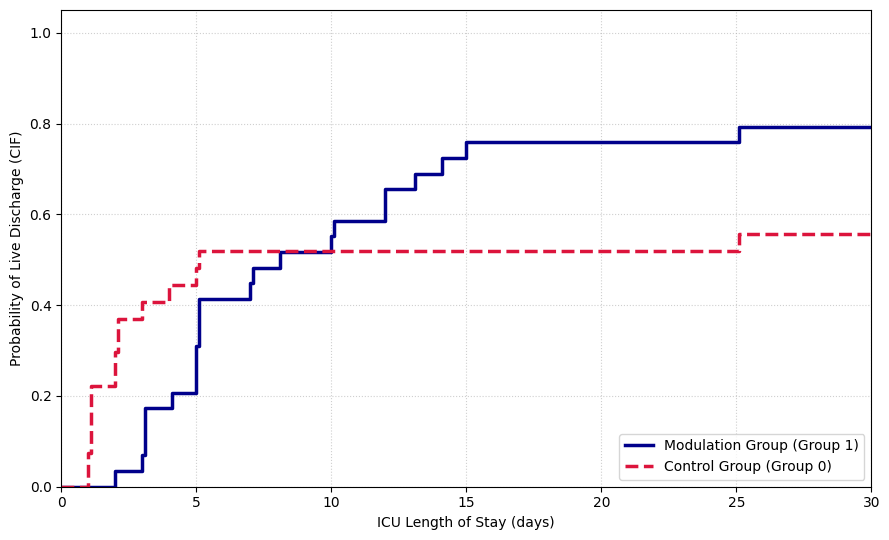

In [56]:
# @title Execute Competing Risk Analysis (Fine-Gray Model)
# Execute the complete Fine-Gray analysis pipeline including continuous plotting
model_summary, shr_results = run_complete_fine_gray_analysis(
    df=supp,
    duration_col='LOS_ICU',        # ICU length of stay (days)
    mortality_col='Death',         # Mortality status (1 = Deceased, 0 = Survived)
    group_col='Group',             # Intervention allocation (1 = Modulation, 0 = Control)
    confounders=confs
)
